## Analysis extension 7 

AE7 addresses the final geometry objection: a query cell can appear "development-unexplained" under one **global linear developmental PCA subspace** simply because normal development is curved. The primary analysis therefore replaces the single global plane with **local developmental tangent spaces**.

The cleanest test uses the two **development-only MLM encoders** from AE1b. Tumour cells did not influence these representations, and the exact adult-normal frozen-query embeddings exported by AE5 are reused rather than re-encoded.

For each audited development-only seed, AE7 asks:

1. **Local calibration:** how well are held-out development, adult normal pancreas, Burdziak N1/N2, the K-series, and overt K5–K6 accommodated by nearby developmental tangent spaces?
2. **Malignant displacement capture:** how much of the sample-equal early, late, and total malignant-state displacement vectors lies in the local developmental tangent around the corresponding source state?
3. **Null and sensitivity:** is that local tangent capture larger than expected from a random subspace of the same dimension, and does it persist across neighbourhood size / tangent dimension?
4. **Biological composition:** which developmental states and developmental days actually define the local tangents?

A joint-MLM tangent analysis is retained only as a **secondary** comparison. No model is retrained in AE7.

(*note that in the notebook last running AE was labeled WP, work_package*)


## 1. Libraries and audited paths

AE1b's `manifest.json` is the single source of truth for the clean developmental/Burdziak matrices and MLM model directories. All outputs are written under the audited revision tree.


In [ ]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

from sklearn.neighbors import NearestNeighbors
from scipy.stats import beta as beta_dist

RANDOM_SEED = 13
DEV_REFERENCE_FRACTION = 0.80

COMMONPATH = Path("/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data")
AUDITED_ROOT = COMMONPATH / "revision_audited_mlm"
MANIFEST_PATH = AUDITED_ROOT / "manifest.json"

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH}\nRun the definitive AE1b audited retraining first."
    )

with open(MANIFEST_PATH) as f:
    AUDIT_MANIFEST = json.load(f)

DEV_H5AD = Path(AUDIT_MANIFEST["dev_h5ad"])
CANCER_H5AD = Path(AUDIT_MANIFEST["cancer_h5ad"])

DEVONLY_SEEDS = [int(x) for x in AUDIT_MANIFEST["seeds"]]
PRIMARY_JOINT_SEED = 17

DEVONLY_MODEL_DIRS = {
    seed: Path(AUDIT_MANIFEST["models"]["development_only"][str(seed)])
    for seed in DEVONLY_SEEDS
}
JOINT_MODEL_DIR = Path(
    AUDIT_MANIFEST["models"]["joint"][str(PRIMARY_JOINT_SEED)]
)

AE5_OUT = AUDITED_ROOT / "analysis" / "ae5_adult_normal_calibration"
AE5_ADULT_CACHE = AE5_OUT / "ae5_adult_cls_for_ae7.npz"
AE5_ADULT_META = AE5_OUT / "ae5_adult_obs_for_ae7.csv"

OUTDIR = AUDITED_ROOT / "analysis" / "ae7_curved_developmental_manifold"
OUTDIR.mkdir(parents=True, exist_ok=True)

# Primary local-manifold settings.
K_LOCAL = 50
Q_LOCAL = 10
N_CALIBRATION_PER_GROUP = 600
N_TANGENT_PER_SAMPLE = 75

# Sensitivity settings. q must be < k; invalid pairs are skipped.
K_GRID = [25, 50, 100, 200]
Q_GRID = [5, 10, 20, 30]
N_SENSITIVITY_PER_SAMPLE = 30

print("Audited root:       ", AUDITED_ROOT)
print("Development matrix:", DEV_H5AD)
print("Burdziak matrix:   ", CANCER_H5AD)
print("Development-only models:")
for seed, p in DEVONLY_MODEL_DIRS.items():
    print(f"  seed {seed}: {p}")
print("Primary joint model:", JOINT_MODEL_DIR)
print("AE5 adult cache:    ", AE5_ADULT_CACHE)
print("AE7 output dir:     ", OUTDIR)


Audited root:        /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm
Development matrix: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/development/A_dev_aligned_clean.h5ad
Burdziak matrix:    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/pdac/A_cancer_aligned_clean.h5ad
Development-only models:
  seed 17: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/development_only/seed_17/model
  seed 42: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/development_only/seed_42/model
Primary joint model: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_17/model
WP5 adult cache:     /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp5_adult_normal_calibration/wp5_adult_cls_for_wp7.npz
WP7 output dir:      /home/jfpoyatos/Work/MNCN_24_25/Develop

## 2. Load clean matrices and exact AE5 adult-query cache

The AnnData matrices are used only for metadata/provenance here; AE7 operates in the frozen MLM CLS spaces. Adult normal coordinates come directly from AE5's exported frozen-query cache.


In [ ]:
A_dev = sc.read_h5ad(DEV_H5AD)
A_can = sc.read_h5ad(CANCER_H5AD)

assert A_dev.shape == (34760, 15376), A_dev.shape
assert A_can.shape == (28131, 15376), A_can.shape
assert np.array_equal(
    A_dev.var_names.astype(str).to_numpy(),
    A_can.var_names.astype(str).to_numpy(),
)

required_can_cols = ["condition", "cancer_state", "batch"]
missing = [c for c in required_can_cols if c not in A_can.obs.columns]
if missing:
    raise KeyError(f"Missing Burdziak metadata columns: {missing}")

if not AE5_ADULT_CACHE.exists() or not AE5_ADULT_META.exists():
    raise FileNotFoundError(
        "AE5 adult cache/metadata is missing. Run definitive AE5 first."
    )

adult_cache = np.load(AE5_ADULT_CACHE)
adult_obs = pd.read_csv(AE5_ADULT_META, index_col=0)

assert adult_obs.index.is_unique
assert "adult_lineage" in adult_obs.columns
assert len(adult_obs) == 1395, len(adult_obs)

print("Development:", A_dev.shape)
print("Burdziak:   ", A_can.shape)
print("Adult meta: ", adult_obs.shape)
print("Adult lineages:")
print(adult_obs["adult_lineage"].astype(str).value_counts())
print("Adult cache arrays:")
for key in adult_cache.files:
    print(" ", key, adult_cache[key].shape)


Development: (34760, 15376)
Burdziak:    (28131, 15376)
Adult meta:  (1395, 28)
Adult lineages:
adult_lineage
endocrine    1052
acinar        182
ductal        161
Name: count, dtype: int64
Adult cache arrays:
  joint_seed17__adult__DEV (1395, 256)
  joint_seed17__adult__CANCER (1395, 256)
  joint_seed42__adult__DEV (1395, 256)
  joint_seed42__adult__CANCER (1395, 256)
  development_only_seed17__adult__DEV (1395, 256)
  development_only_seed42__adult__DEV (1395, 256)


## 3. Load definitive CLS embeddings with exact row-order checks

Every developmental/Burdziak embedding is read from the AE1b model directory that created it. Cell-name arrays saved by AE1b must match the clean AnnData objects exactly.


In [ ]:
def load_audited_cls(model_dir):
    model_dir = Path(model_dir)

    Xd = np.load(model_dir / "X_dev_cls.npy").astype(np.float32)
    Xc = np.load(model_dir / "X_cancer_cls.npy").astype(np.float32)

    dev_names = np.load(
        model_dir / "dev_obs_names.npy",
        allow_pickle=True,
    ).astype(str)
    can_names = np.load(
        model_dir / "cancer_obs_names.npy",
        allow_pickle=True,
    ).astype(str)

    expected_dev = A_dev.obs_names.astype(str).to_numpy()
    expected_can = A_can.obs_names.astype(str).to_numpy()

    if not np.array_equal(dev_names, expected_dev):
        raise ValueError(f"DEV cell-order mismatch in {model_dir}")
    if not np.array_equal(can_names, expected_can):
        raise ValueError(f"Burdziak cell-order mismatch in {model_dir}")

    if Xd.shape[0] != A_dev.n_obs or Xc.shape[0] != A_can.n_obs:
        raise ValueError(f"Embedding row-count mismatch in {model_dir}")
    if Xd.shape[1] != Xc.shape[1]:
        raise ValueError(f"Embedding dimension mismatch in {model_dir}")

    return Xd, Xc


def adult_embedding_for_devonly(seed):
    key = f"development_only_seed{seed}__adult__DEV"
    if key not in adult_cache.files:
        raise KeyError(f"Missing AE5 adult cache key: {key}")
    X = adult_cache[key].astype(np.float32)
    if X.shape[0] != len(adult_obs):
        raise ValueError(f"Adult row-count mismatch for {key}: {X.shape}")
    return X


def adult_embedding_for_joint(seed, domain="DEV"):
    key = f"joint_seed{seed}__adult__{domain}"
    if key not in adult_cache.files:
        raise KeyError(f"Missing AE5 adult cache key: {key}")
    X = adult_cache[key].astype(np.float32)
    if X.shape[0] != len(adult_obs):
        raise ValueError(f"Adult row-count mismatch for {key}: {X.shape}")
    return X

DEVONLY_EMB = {}
for seed in DEVONLY_SEEDS:
    Xd, Xc = load_audited_cls(DEVONLY_MODEL_DIRS[seed])
    Xa = adult_embedding_for_devonly(seed)
    assert Xd.shape[1] == Xa.shape[1]
    DEVONLY_EMB[seed] = {"dev": Xd, "cancer": Xc, "adult": Xa}
    print(
        f"development_only seed {seed}: DEV {Xd.shape}, "
        f"CANCER {Xc.shape}, ADULT {Xa.shape}"
    )

X_joint_dev, X_joint_can = load_audited_cls(JOINT_MODEL_DIR)
print(
    f"joint seed {PRIMARY_JOINT_SEED}: DEV {X_joint_dev.shape}, "
    f"CANCER {X_joint_can.shape}"
)


development_only seed 17: DEV (34760, 256), CANCER (28131, 256), ADULT (1395, 256)
development_only seed 42: DEV (34760, 256), CANCER (28131, 256), ADULT (1395, 256)
joint seed 17: DEV (34760, 256), CANCER (28131, 256)


## 4. Reproduce the exact AE5 developmental split and final AE3 biological definitions

The developmental reference/holdout split is copied exactly from definitive AE5: stratify by developmental identity × day, use a fresh seed-13 generator, and take 80% per stratum. The final AE3 developmental-state definitions and Burdziak biological-sample convention are also reproduced with explicit count assertions.


In [ ]:
def choose_dev_label_col(obs):
    for c in [
        "dev_state_union",
        "celltype_update",
        "endo_category",
        "dev_tier",
        "cell_type",
        "celltype",
    ]:
        if c in obs.columns:
            return c
    raise KeyError("No developmental identity column found.")


def choose_stage_col(obs):
    for c in [
        "day",
        "stage",
        "developmental_stage",
        "embryonic_day",
        "timepoint",
    ]:
        if c in obs.columns:
            return c
    return None


def choose_ae3_day_col(obs):
    for c in [
        "dev_day",
        "day",
        "stage",
        "developmental_stage",
        "embryonic_day",
        "timepoint",
    ]:
        if c in obs.columns:
            return c
    raise KeyError("No developmental day column found for AE3 states.")

DEV_LABEL_COL = choose_dev_label_col(A_dev.obs)
DEV_SPLIT_DAY_COL = choose_stage_col(A_dev.obs)
DEV_DAY_COL = choose_ae3_day_col(A_dev.obs)

split_rng = np.random.default_rng(RANDOM_SEED)
strata = A_dev.obs[DEV_LABEL_COL].astype(str)
if DEV_SPLIT_DAY_COL is not None:
    strata = strata + "|" + A_dev.obs[DEV_SPLIT_DAY_COL].astype(str)

ref_idx = []
hold_idx = []
for _, pos in pd.Series(
    np.arange(A_dev.n_obs),
    index=A_dev.obs_names,
).groupby(strata.values):
    ids = pos.to_numpy()
    split_rng.shuffle(ids)
    if len(ids) == 1:
        ref_idx.extend(ids)
        continue
    n_ref = max(
        1,
        min(
            len(ids) - 1,
            int(np.floor(DEV_REFERENCE_FRACTION * len(ids))),
        ),
    )
    ref_idx.extend(ids[:n_ref])
    hold_idx.extend(ids[n_ref:])

ref_idx = np.asarray(sorted(ref_idx), dtype=int)
hold_idx = np.asarray(sorted(hold_idx), dtype=int)

assert len(np.intersect1d(ref_idx, hold_idx)) == 0
assert len(ref_idx) == 27678, len(ref_idx)
assert len(hold_idx) == 7082, len(hold_idx)

split_table = pd.DataFrame({
    "cell_id": A_dev.obs_names.astype(str),
    "ae5_reference": np.isin(np.arange(A_dev.n_obs), ref_idx),
    "ae5_heldout": np.isin(np.arange(A_dev.n_obs), hold_idx),
    "stratum": strata.to_numpy(),
})
split_table.to_csv(OUTDIR / "ae7_shared_ae5_developmental_split.csv", index=False)

print("Developmental identity:", DEV_LABEL_COL)
print("Split day column:       ", DEV_SPLIT_DAY_COL)
print("AE3 day column:         ", DEV_DAY_COL)
print("Reference developmental cells:", len(ref_idx))
print("Held-out developmental cells: ", len(hold_idx))


def revised_ae3_masks(dev_obs):
    ct = dev_obs["celltype_update"].astype(str)
    day = pd.to_numeric(dev_obs[DEV_DAY_COL], errors="coerce")
    return {
        "MPC_like": ((ct == "Pancreatic acinar cells") & (day <= 11.5)).to_numpy(),
        "tip_acinar": (
            (ct == "Pancreatic acinar cells")
            & (day >= 13.75)
            & (day <= 16.5)
        ).to_numpy(),
        "endocrine_secondary": (
            (ct == "Pancreatic islets")
            & (day >= 13.75)
            & (day <= 16.5)
        ).to_numpy(),
        "endocrine_late": (
            (ct == "Pancreatic islets")
            & (day >= 16.75)
        ).to_numpy(),
        "biliary_early": (
            (ct == "Biliary epithelial cells")
            & (day >= 11.75)
            & (day <= 13.5)
        ).to_numpy(),
        "biliary_secondary": (
            (ct == "Biliary epithelial cells")
            & (day >= 13.75)
            & (day <= 16.5)
        ).to_numpy(),
    }

AE3_STATE_MASKS = revised_ae3_masks(A_dev.obs)
EXPECTED_AE3_STATE_COUNTS = {
    "MPC_like": 164,
    "tip_acinar": 2871,
    "endocrine_secondary": 633,
    "endocrine_late": 556,
    "biliary_early": 126,
    "biliary_secondary": 601,
}
observed_counts = {k: int(v.sum()) for k, v in AE3_STATE_MASKS.items()}
assert observed_counts == EXPECTED_AE3_STATE_COUNTS, observed_counts

SAMPLE_COL = "batch"
CANCER_STATE_ORDER = ["ductal", "transitional", "malignant_ductal"]
EXPECTED_SAMPLE_COUNTS = {"ductal": 4, "transitional": 11, "malignant_ductal": 6}
sample_counts = {
    state: int(
        A_can.obs.loc[
            A_can.obs["cancer_state"].astype(str).eq(state),
            SAMPLE_COL,
        ].astype(str).nunique()
    )
    for state in CANCER_STATE_ORDER
}
assert sample_counts == EXPECTED_SAMPLE_COUNTS, sample_counts

print("AE3 developmental-state counts:", observed_counts)
print("Burdziak biological samples per state:", sample_counts)


Developmental identity: dev_state_union
Split day column:        day
WP3 day column:          dev_day
Reference developmental cells: 27678
Held-out developmental cells:  7082
WP3 developmental-state counts: {'MPC_like': 164, 'tip_acinar': 2871, 'endocrine_secondary': 633, 'endocrine_late': 556, 'biliary_early': 126, 'biliary_secondary': 601}
Burdziak biological samples per state: {'ductal': 4, 'transitional': 11, 'malignant_ductal': 6}


## 5. Local tangent helpers

For a query cell, the `k` nearest **reference developmental** cells define a local neighbourhood. Its centered SVD supplies a `q`-dimensional tangent basis. We measure both the fraction of query displacement captured by that tangent and the orthogonal distance left outside it.


In [5]:
def local_tangent(neigh_points, q):
    X = np.asarray(neigh_points, dtype=np.float32)
    center = X.mean(axis=0)
    Y = X - center
    max_rank = min(Y.shape[0] - 1, Y.shape[1])
    q_eff = min(int(q), max_rank)
    if q_eff < 1:
        raise ValueError("Local tangent rank is zero.")

    _, s, vt = np.linalg.svd(Y, full_matrices=False)
    basis = vt[:q_eff].T
    denom = float(np.sum(s ** 2))
    ev = np.nan if denom <= 0 else float(np.sum(s[:q_eff] ** 2) / denom)
    return center, basis, ev


def projection_fraction(v, basis):
    v = np.asarray(v, dtype=np.float64)
    total2 = float(np.dot(v, v))
    if total2 <= 1e-12:
        return np.nan
    coeff = basis.T @ v
    return float(np.dot(coeff, coeff) / total2)


def fit_dev_nn(X_reference, k):
    if k >= len(X_reference):
        raise ValueError("k must be smaller than the developmental reference size.")
    return NearestNeighbors(
        n_neighbors=int(k),
        metric="euclidean",
        n_jobs=-1,
    ).fit(X_reference)


def deterministic_subsample(idx, n_max, seed):
    idx = np.asarray(idx, dtype=int)
    if len(idx) <= n_max:
        return idx
    rr = np.random.default_rng(int(seed))
    return np.sort(rr.choice(idx, size=int(n_max), replace=False))


def local_query_metrics(X_query, query_ids, sample_ids, nn_reference, X_reference, q):
    X_query = np.asarray(X_query, dtype=np.float32)
    dist, inds = nn_reference.kneighbors(X_query, return_distance=True)
    rows = []

    for i in range(X_query.shape[0]):
        neigh = X_reference[inds[i]]
        center, basis, local_ev = local_tangent(neigh, q)
        d = X_query[i] - center
        q_local = projection_fraction(d, basis)
        proj = basis @ (basis.T @ d)
        resid = d - proj

        rows.append({
            "query_id": str(query_ids[i]),
            "sample_id": str(sample_ids[i]),
            "nearest_dev_distance": float(dist[i, 0]),
            "local_projection_fraction": q_local,
            "local_residual_fraction": (
                np.nan if not np.isfinite(q_local) else 1.0 - q_local
            ),
            "local_tangent_distance": float(np.linalg.norm(resid)),
            "local_tangent_variance_fraction": float(local_ev),
        })

    return pd.DataFrame(rows)


def sample_equal_state_centroids(Xc):
    Xc = np.asarray(Xc, dtype=np.float32)
    obs = A_can.obs.copy()
    obs["_row_position"] = np.arange(A_can.n_obs)
    C = {}

    for state in CANCER_STATE_ORDER:
        sub = obs.loc[obs["cancer_state"].astype(str).eq(state)]
        sample_means = []
        for _, g in sub.groupby(SAMPLE_COL, observed=True, sort=False):
            pos = g["_row_position"].to_numpy(dtype=int)
            sample_means.append(Xc[pos].mean(axis=0))
        if not sample_means:
            raise ValueError(f"No samples for state {state}")
        C[state] = np.mean(np.stack(sample_means), axis=0)

    return C


def malignant_vectors_sample_equal(Xc):
    C = sample_equal_state_centroids(Xc)
    return {
        "early": C["transitional"] - C["ductal"],
        "late": C["malignant_ductal"] - C["transitional"],
        "total": C["malignant_ductal"] - C["ductal"],
    }

TRANSITION_SOURCE = {
    "early": "ductal",
    "late": "transitional",
    "total": "ductal",
}


def balanced_source_positions(state, n_per_sample, seed):
    obs = A_can.obs.copy()
    obs["_row_position"] = np.arange(A_can.n_obs)
    sub = obs.loc[obs["cancer_state"].astype(str).eq(state)]
    out = []
    rr = np.random.default_rng(int(seed))

    for sample, g in sub.groupby(SAMPLE_COL, observed=True, sort=True):
        pos = g["_row_position"].to_numpy(dtype=int)
        take = min(int(n_per_sample), len(pos))
        chosen = pos if take == len(pos) else rr.choice(pos, size=take, replace=False)
        out.extend((int(x), str(sample)) for x in chosen)

    return out


# Part I — Primary development-only local-manifold calibration

The developmental neighbour search is fit **only on the AE5 reference 80%**. Held-out development is therefore genuinely out of reference, just like adult normal and Burdziak cells.


In [ ]:
condition_can = A_can.obs["condition"].astype(str).to_numpy()
adult_lineage = adult_obs["adult_lineage"].astype(str).to_numpy()

calibration_rows = []

for seed in DEVONLY_SEEDS:
    print("\n" + "=" * 80)
    print("DEVELOPMENT-ONLY SEED", seed)
    print("=" * 80)

    Xd = DEVONLY_EMB[seed]["dev"]
    Xc = DEVONLY_EMB[seed]["cancer"]
    Xa = DEVONLY_EMB[seed]["adult"]

    Xref = Xd[ref_idx]
    nn_ref = fit_dev_nn(Xref, K_LOCAL)

    group_specs = [
        (
            "heldout_development",
            Xd,
            hold_idx,
            A_dev.obs_names.astype(str).to_numpy(),
            A_dev.obs[DEV_DAY_COL].astype(str).to_numpy(),
        ),
        (
            "adult_acinar",
            Xa,
            np.where(adult_lineage == "acinar")[0],
            adult_obs.index.astype(str).to_numpy(),
            adult_obs.get("mouse.id", pd.Series("NA", index=adult_obs.index)).astype(str).to_numpy(),
        ),
        (
            "adult_ductal",
            Xa,
            np.where(adult_lineage == "ductal")[0],
            adult_obs.index.astype(str).to_numpy(),
            adult_obs.get("mouse.id", pd.Series("NA", index=adult_obs.index)).astype(str).to_numpy(),
        ),
        (
            "adult_endocrine",
            Xa,
            np.where(adult_lineage == "endocrine")[0],
            adult_obs.index.astype(str).to_numpy(),
            adult_obs.get("mouse.id", pd.Series("NA", index=adult_obs.index)).astype(str).to_numpy(),
        ),
        (
            "Burdziak_N1",
            Xc,
            np.where(condition_can == "N1")[0],
            A_can.obs_names.astype(str).to_numpy(),
            A_can.obs[SAMPLE_COL].astype(str).to_numpy(),
        ),
        (
            "Burdziak_N2",
            Xc,
            np.where(condition_can == "N2")[0],
            A_can.obs_names.astype(str).to_numpy(),
            A_can.obs[SAMPLE_COL].astype(str).to_numpy(),
        ),
        (
            "K_series_all",
            Xc,
            np.where(np.char.startswith(condition_can.astype(str), "K"))[0],
            A_can.obs_names.astype(str).to_numpy(),
            A_can.obs[SAMPLE_COL].astype(str).to_numpy(),
        ),
        (
            "overt_K5_K6",
            Xc,
            np.where(np.isin(condition_can, ["K5", "K6"]))[0],
            A_can.obs_names.astype(str).to_numpy(),
            A_can.obs[SAMPLE_COL].astype(str).to_numpy(),
        ),
    ]

    for gi, (group, Xall, idx, ids_all, samples_all) in enumerate(group_specs):
        use = deterministic_subsample(
            idx,
            N_CALIBRATION_PER_GROUP,
            RANDOM_SEED + seed * 100 + gi,
        )

        if len(use) == 0:
            raise ValueError(f"Empty calibration group: {group}")

        m = local_query_metrics(
            Xall[use],
            ids_all[use],
            samples_all[use],
            nn_ref,
            Xref,
            Q_LOCAL,
        )
        m.insert(0, "group", group)
        m.insert(0, "seed", seed)
        calibration_rows.append(m)
        print(group, len(use), "median local projection =", round(m["local_projection_fraction"].median(), 4))

calibration_cells = pd.concat(calibration_rows, ignore_index=True)
calibration_cells.to_csv(
    OUTDIR / "ae7_primary_devonly_local_calibration_cells.csv.gz",
    index=False,
    compression="gzip",
)

calibration_summary = (
    calibration_cells
    .groupby(["seed", "group"], observed=True)
    .agg(
        n=("local_projection_fraction", "size"),
        median_local_projection_fraction=("local_projection_fraction", "median"),
        q25_local_projection_fraction=("local_projection_fraction", lambda x: np.quantile(x, 0.25)),
        q75_local_projection_fraction=("local_projection_fraction", lambda x: np.quantile(x, 0.75)),
        median_local_tangent_distance=("local_tangent_distance", "median"),
        median_nearest_dev_distance=("nearest_dev_distance", "median"),
        median_local_tangent_variance=("local_tangent_variance_fraction", "median"),
    )
    .reset_index()
)
calibration_summary.to_csv(
    OUTDIR / "ae7_primary_devonly_local_calibration_summary.csv",
    index=False,
)

display(calibration_summary.round(4))



DEVELOPMENT-ONLY SEED 17
heldout_development 600 median local projection = 0.4747
adult_acinar 182 median local projection = 0.521
adult_ductal 161 median local projection = 0.2561
adult_endocrine 600 median local projection = 0.2786
Burdziak_N1 600 median local projection = 0.4068
Burdziak_N2 600 median local projection = 0.3372
K_series_all 600 median local projection = 0.2945
overt_K5_K6 600 median local projection = 0.2973

DEVELOPMENT-ONLY SEED 42
heldout_development 600 median local projection = 0.4305
adult_acinar 182 median local projection = 0.4042
adult_ductal 161 median local projection = 0.1988
adult_endocrine 600 median local projection = 0.206
Burdziak_N1 600 median local projection = 0.3528
Burdziak_N2 600 median local projection = 0.3191
K_series_all 600 median local projection = 0.2089
overt_K5_K6 600 median local projection = 0.2083


,seed,group,n,median_local_projection_fraction,q25_local_projection_fraction,q75_local_projection_fraction,median_local_tangent_distance,median_nearest_dev_distance,median_local_tangent_variance
0,17,Burdziak_N1,600,0.4068,0.2835,0.5586,4.2343,5.8125,0.8455
1,17,Burdziak_N2,600,0.3372,0.2710,0.4104,4.1990,5.4983,0.7856
2,17,K_series_all,600,0.2945,0.2351,0.3434,4.3323,4.5583,0.7840
3,17,adult_acinar,182,0.5210,0.4624,0.5734,3.3657,4.6735,0.8126
4,17,adult_ductal,161,0.2561,0.2052,0.2956,4.0222,4.2897,0.7760
5,17,adult_endocrine,600,0.2786,0.2361,0.3271,3.7369,5.2287,0.8015
6,17,heldout_development,600,0.4747,0.3772,0.5775,1.6453,2.6726,0.8283
7,17,overt_K5_K6,600,0.2973,0.2496,0.3387,4.3541,4.5890,0.7841
8,42,Burdziak_N1,600,0.3528,0.2780,0.4785,3.7940,4.9208,0.8365
9,42,Burdziak_N2,600,0.3191,0.2293,0.4185,3.7244,5.0255,0.8132


### Sample-level calibration summary

For adult and Burdziak groups, one median is first calculated per mouse / Burdziak `batch`, then samples are summarized with equal weight. This is descriptive calibration, not a formal biological-replicate test for held-out embryonic cells.


,seed,group,n_samples,equal_sample_mean_projection,equal_sample_median_projection,equal_sample_mean_tangent_distance
0,17,Burdziak_N1,2,0.4196,0.4196,4.2123
1,17,Burdziak_N2,2,0.3367,0.3367,4.2102
2,17,K_series_all,17,0.2950,0.2909,4.3363
3,17,adult_acinar,4,0.5147,0.5158,3.3606
4,17,adult_ductal,4,0.2514,0.2530,3.9928
5,17,adult_endocrine,4,0.2806,0.2788,3.7363
6,17,overt_K5_K6,6,0.2904,0.2946,4.3723
7,42,Burdziak_N1,2,0.3528,0.3528,3.7926
8,42,Burdziak_N2,2,0.3234,0.3234,3.7289
9,42,K_series_all,17,0.2115,0.2055,3.8584


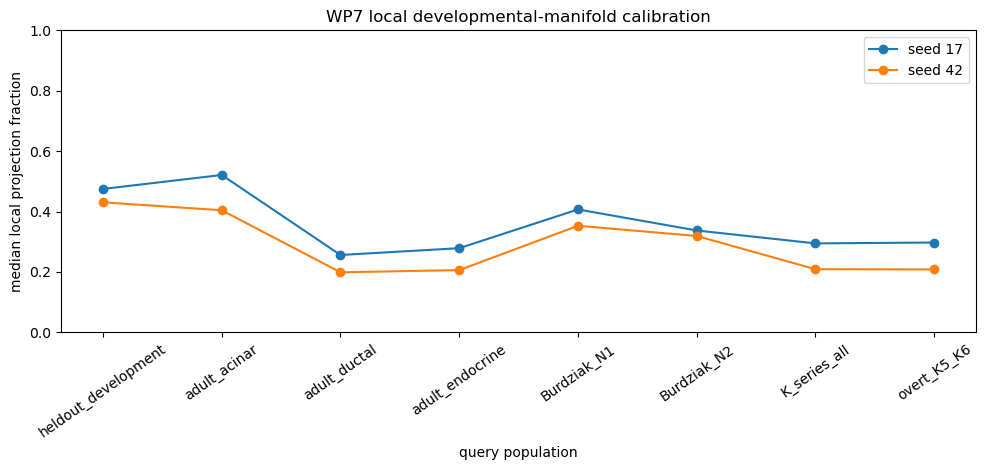

In [ ]:
sample_eligible = ~calibration_cells["group"].eq("heldout_development")
cal_sample = (
    calibration_cells.loc[sample_eligible]
    .groupby(["seed", "group", "sample_id"], observed=True)
    .agg(
        n_cells=("local_projection_fraction", "size"),
        sample_median_local_projection=("local_projection_fraction", "median"),
        sample_median_local_tangent_distance=("local_tangent_distance", "median"),
    )
    .reset_index()
)
cal_sample.to_csv(
    OUTDIR / "ae7_primary_devonly_local_calibration_by_sample.csv",
    index=False,
)

cal_sample_summary = (
    cal_sample
    .groupby(["seed", "group"], observed=True)
    .agg(
        n_samples=("sample_id", "nunique"),
        equal_sample_mean_projection=("sample_median_local_projection", "mean"),
        equal_sample_median_projection=("sample_median_local_projection", "median"),
        equal_sample_mean_tangent_distance=("sample_median_local_tangent_distance", "mean"),
    )
    .reset_index()
)
cal_sample_summary.to_csv(
    OUTDIR / "ae7_primary_devonly_local_calibration_sample_summary.csv",
    index=False,
)

display(cal_sample_summary.round(4))

# Compact figure.
order = [
    "heldout_development",
    "adult_acinar",
    "adult_ductal",
    "adult_endocrine",
    "Burdziak_N1",
    "Burdziak_N2",
    "K_series_all",
    "overt_K5_K6",
]
fig, ax = plt.subplots(figsize=(10, 4.8))
for seed in DEVONLY_SEEDS:
    s = calibration_summary[calibration_summary["seed"] == seed].set_index("group").reindex(order)
    ax.plot(order, s["median_local_projection_fraction"], marker="o", label=f"seed {seed}")
ax.set_ylim(0, 1)
ax.set_ylabel("median local projection fraction")
ax.set_xlabel("query population")
ax.set_title("AE7 local developmental-manifold calibration")
ax.tick_params(axis="x", rotation=35)
ax.legend()
plt.tight_layout()
fig.savefig(OUTDIR / "ae7_primary_local_calibration.png", dpi=180, bbox_inches="tight")
plt.show()


# Part II — Primary malignant-displacement capture by local developmental tangents

The early/late/total malignant vectors use **equal biological-sample centroids**, exactly as in final AE3/AE6. Local tangents are evaluated around source-state cancer cells sampled with equal maximum contribution from each Burdziak biological sample.


In [ ]:
tangent_rows = []

for seed in DEVONLY_SEEDS:
    Xd = DEVONLY_EMB[seed]["dev"]
    Xc = DEVONLY_EMB[seed]["cancer"]
    Xref = Xd[ref_idx]
    nn_ref = fit_dev_nn(Xref, K_LOCAL)
    vectors = malignant_vectors_sample_equal(Xc)

    # Reuse local tangents for transitions sharing the same source state.
    source_cache = {}
    for source_state in sorted(set(TRANSITION_SOURCE.values())):
        pairs = balanced_source_positions(
            source_state,
            N_TANGENT_PER_SAMPLE,
            RANDOM_SEED + seed * 1000 + CANCER_STATE_ORDER.index(source_state),
        )
        pos = np.array([p for p, _ in pairs], dtype=int)
        sam = np.array([s for _, s in pairs], dtype=object)
        _, inds = nn_ref.kneighbors(Xc[pos], return_distance=True)

        bases = []
        local_ev = []
        for i in range(len(pos)):
            _, basis, ev = local_tangent(Xref[inds[i]], Q_LOCAL)
            bases.append(basis)
            local_ev.append(ev)
        source_cache[source_state] = (pos, sam, bases, np.asarray(local_ev))

    for transition in ["early", "late", "total"]:
        source_state = TRANSITION_SOURCE[transition]
        v = vectors[transition]
        pos, sam, bases, local_ev = source_cache[source_state]

        for j, sample, basis, ev in zip(pos, sam, bases, local_ev):
            tangent_rows.append({
                "seed": seed,
                "transition": transition,
                "source_state": source_state,
                "source_cell_index": int(j),
                "source_cell_id": str(A_can.obs_names[j]),
                "source_sample": str(sample),
                "tangent_fraction": projection_fraction(v, basis),
                "local_tangent_variance_fraction": float(ev),
            })

tangent_cells = pd.DataFrame(tangent_rows)
tangent_cells.to_csv(
    OUTDIR / "ae7_primary_devonly_tangent_capture_cells.csv.gz",
    index=False,
    compression="gzip",
)

# Equal-sample summary: one median tangent fraction per biological sample first.
tangent_by_sample = (
    tangent_cells
    .groupby(["seed", "transition", "source_state", "source_sample"], observed=True)
    .agg(
        n_cells=("tangent_fraction", "size"),
        sample_median_tangent_fraction=("tangent_fraction", "median"),
        sample_median_local_variance=("local_tangent_variance_fraction", "median"),
    )
    .reset_index()
)
tangent_by_sample.to_csv(
    OUTDIR / "ae7_primary_devonly_tangent_capture_by_sample.csv",
    index=False,
)

tangent_summary = (
    tangent_by_sample
    .groupby(["seed", "transition", "source_state"], observed=True)
    .agg(
        n_samples=("source_sample", "nunique"),
        sample_equal_median_tangent_fraction=("sample_median_tangent_fraction", "median"),
        sample_equal_mean_tangent_fraction=("sample_median_tangent_fraction", "mean"),
        q25_sample_medians=("sample_median_tangent_fraction", lambda x: np.quantile(x, 0.25)),
        q75_sample_medians=("sample_median_tangent_fraction", lambda x: np.quantile(x, 0.75)),
        median_local_tangent_variance=("sample_median_local_variance", "median"),
    )
    .reset_index()
)
tangent_summary.to_csv(
    OUTDIR / "ae7_primary_devonly_tangent_capture_summary.csv",
    index=False,
)

display(tangent_summary.round(4))


,seed,transition,source_state,n_samples,sample_equal_median_tangent_fraction,sample_equal_mean_tangent_fraction,q25_sample_medians,q75_sample_medians,median_local_tangent_variance
0,17,early,ductal,4,0.5243,0.5340,0.4488,0.6096,0.8240
1,17,late,transitional,11,0.3511,0.3591,0.3366,0.3723,0.7835
2,17,total,ductal,4,0.5060,0.5150,0.4211,0.5999,0.8240
3,42,early,ductal,4,0.5096,0.5303,0.4668,0.5731,0.8245
4,42,late,transitional,11,0.3484,0.3481,0.3414,0.3542,0.7911
5,42,total,ductal,4,0.4882,0.5099,0.4431,0.5550,0.8245


## 8. Matched-dimensional random-subspace benchmark

For a fixed vector in ambient dimension `D`, the fraction of squared norm captured by a uniformly random `q`-dimensional subspace follows `Beta(q/2, (D-q)/2)`. This provides an exact geometric benchmark for the observed local-tangent capture. The percentile is descriptive; it is not treated as a biological-replicate p-value.


,seed,transition,source_state,D,q,observed_sample_equal_median,random_mean,random_median,random_q025,random_q975,observed_over_random_mean,random_null_percentile
0,17,early,ductal,256,10,0.5243,0.0391,0.0367,0.0129,0.0787,13.4230,1.0
1,17,late,transitional,256,10,0.3511,0.0391,0.0367,0.0129,0.0787,8.9871,1.0
2,17,total,ductal,256,10,0.5060,0.0391,0.0367,0.0129,0.0787,12.9529,1.0
3,42,early,ductal,256,10,0.5096,0.0391,0.0367,0.0129,0.0787,13.0466,1.0
4,42,late,transitional,256,10,0.3484,0.0391,0.0367,0.0129,0.0787,8.9188,1.0
5,42,total,ductal,256,10,0.4882,0.0391,0.0367,0.0129,0.0787,12.4986,1.0


Random 10-D subspace in D=256: expected capture = 0.0391


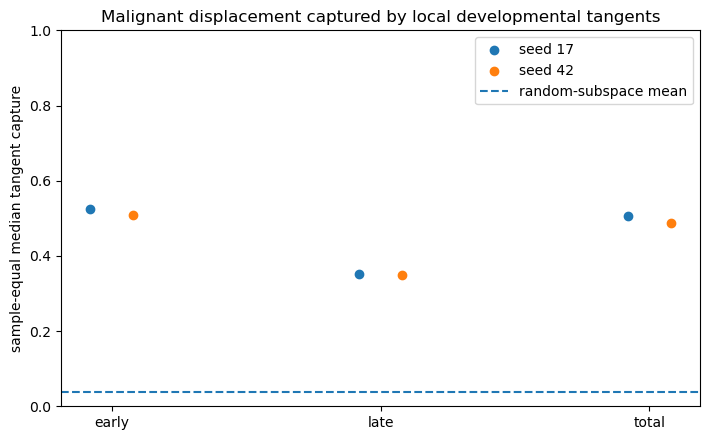

In [ ]:
D = int(DEVONLY_EMB[DEVONLY_SEEDS[0]]["dev"].shape[1])
q = int(Q_LOCAL)
null_mean = q / D
null_q025 = float(beta_dist.ppf(0.025, q / 2.0, (D - q) / 2.0))
null_q50 = float(beta_dist.ppf(0.50, q / 2.0, (D - q) / 2.0))
null_q975 = float(beta_dist.ppf(0.975, q / 2.0, (D - q) / 2.0))

null_rows = []
for _, r in tangent_summary.iterrows():
    obs = float(r["sample_equal_median_tangent_fraction"])
    null_rows.append({
        "seed": int(r["seed"]),
        "transition": r["transition"],
        "source_state": r["source_state"],
        "D": D,
        "q": q,
        "observed_sample_equal_median": obs,
        "random_mean": null_mean,
        "random_median": null_q50,
        "random_q025": null_q025,
        "random_q975": null_q975,
        "observed_over_random_mean": obs / null_mean,
        "random_null_percentile": float(beta_dist.cdf(obs, q / 2.0, (D - q) / 2.0)),
    })

null_summary = pd.DataFrame(null_rows)
null_summary.to_csv(
    OUTDIR / "ae7_primary_devonly_tangent_random_subspace_null.csv",
    index=False,
)

display(null_summary.round(4))
print(f"Random {q}-D subspace in D={D}: expected capture = {null_mean:.4f}")

fig, ax = plt.subplots(figsize=(7.2, 4.5))
transitions = ["early", "late", "total"]
x = np.arange(len(transitions))
for offset, seed in zip([-0.08, 0.08], DEVONLY_SEEDS):
    s = tangent_summary[tangent_summary["seed"] == seed].set_index("transition").reindex(transitions)
    ax.scatter(x + offset, s["sample_equal_median_tangent_fraction"], label=f"seed {seed}")
ax.axhline(null_mean, linestyle="--", label="random-subspace mean")
ax.set_xticks(x, transitions)
ax.set_ylim(0, 1)
ax.set_ylabel("sample-equal median tangent capture")
ax.set_title("Malignant displacement captured by local developmental tangents")
ax.legend()
plt.tight_layout()
fig.savefig(OUTDIR / "ae7_primary_tangent_capture.png", dpi=180, bbox_inches="tight")
plt.show()


# Part III — Sensitivity to neighbourhood size and tangent dimension

For each `k`, the local SVD is fit once using the largest valid `q`; smaller tangent dimensions use prefixes of the same ordered basis. Source cells are again balanced across Burdziak biological samples.


,seed,transition,source_state,k_neighbors,tangent_dim,n_samples,sample_equal_median_tangent_fraction,sample_equal_mean_tangent_fraction,random_subspace_mean
0,17,early,ductal,25,5,4,0.3802,0.3888,0.0195
1,17,early,ductal,25,10,4,0.5013,0.5101,0.0391
2,17,early,ductal,25,20,4,0.6222,0.6189,0.0781
3,17,total,ductal,25,5,4,0.3593,0.3671,0.0195
4,17,total,ductal,25,10,4,0.4900,0.4984,0.0391
...,...,...,...,...,...,...,...,...,...
85,42,total,ductal,200,30,4,0.8209,0.8270,0.1172
86,42,late,transitional,200,5,11,0.1832,0.1835,0.0195
87,42,late,transitional,200,10,11,0.3021,0.2935,0.0391
88,42,late,transitional,200,20,11,0.6199,0.6182,0.0781


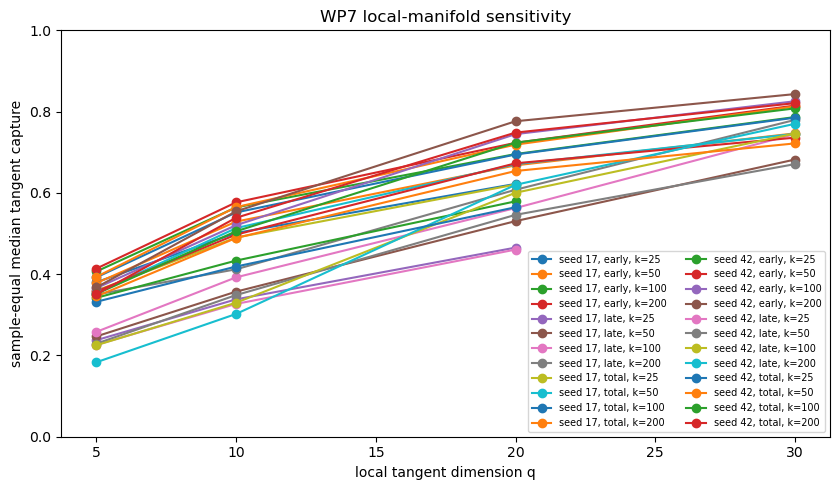

In [ ]:
sens_rows = []

for seed in DEVONLY_SEEDS:
    Xd = DEVONLY_EMB[seed]["dev"]
    Xc = DEVONLY_EMB[seed]["cancer"]
    Xref = Xd[ref_idx]
    vectors = malignant_vectors_sample_equal(Xc)

    source_pairs = {
        state: balanced_source_positions(
            state,
            N_SENSITIVITY_PER_SAMPLE,
            RANDOM_SEED + 7000 + seed * 10 + CANCER_STATE_ORDER.index(state),
        )
        for state in sorted(set(TRANSITION_SOURCE.values()))
    }

    for k in K_GRID:
        nn_ref = fit_dev_nn(Xref, k)

        for source_state, pairs in source_pairs.items():
            pos = np.array([p for p, _ in pairs], dtype=int)
            sam = np.array([s for _, s in pairs], dtype=object)
            _, inds = nn_ref.kneighbors(Xc[pos], return_distance=True)

            valid_q = [q for q in Q_GRID if q < k and q <= Xref.shape[1]]
            if not valid_q:
                continue
            qmax = max(valid_q)

            # Fit one ordered basis per source cell, then reuse prefixes for q sensitivity.
            bases = []
            for i in range(len(pos)):
                _, basis, _ = local_tangent(Xref[inds[i]], qmax)
                bases.append(basis)

            transitions_here = [
                t for t, s in TRANSITION_SOURCE.items() if s == source_state
            ]

            for transition in transitions_here:
                v = vectors[transition]
                for q in valid_q:
                    vals = []
                    for sample, basis in zip(sam, bases):
                        vals.append((str(sample), projection_fraction(v, basis[:, :q])))
                    vv = pd.DataFrame(vals, columns=["sample", "capture"])
                    sample_meds = vv.groupby("sample", observed=True)["capture"].median().to_numpy()
                    sens_rows.append({
                        "seed": seed,
                        "transition": transition,
                        "source_state": source_state,
                        "k_neighbors": k,
                        "tangent_dim": q,
                        "n_samples": len(sample_meds),
                        "sample_equal_median_tangent_fraction": float(np.median(sample_meds)),
                        "sample_equal_mean_tangent_fraction": float(np.mean(sample_meds)),
                        "random_subspace_mean": float(q / Xref.shape[1]),
                    })

sensitivity = pd.DataFrame(sens_rows)
sensitivity.to_csv(
    OUTDIR / "ae7_primary_devonly_tangent_parameter_sensitivity.csv",
    index=False,
)
display(sensitivity.round(4))

fig, ax = plt.subplots(figsize=(8.5, 5.0))
for (seed, transition, k), sub in sensitivity.groupby(["seed", "transition", "k_neighbors"], observed=True):
    sub = sub.sort_values("tangent_dim")
    ax.plot(
        sub["tangent_dim"],
        sub["sample_equal_median_tangent_fraction"],
        marker="o",
        label=f"seed {seed}, {transition}, k={k}",
    )
ax.set_ylim(0, 1)
ax.set_xlabel("local tangent dimension q")
ax.set_ylabel("sample-equal median tangent capture")
ax.set_title("AE7 local-manifold sensitivity")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
fig.savefig(OUTDIR / "ae7_primary_tangent_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()


# Part IV — Biological composition of the local tangents

This diagnostic asks what the local developmental neighbourhoods actually contain. It prevents an abstract geometric result from being interpreted as a pancreatic developmental trajectory when the neighbours are mostly other developmental states.


In [ ]:
ae3_state_label = np.full(A_dev.n_obs, "other_development", dtype=object)
for name, mask in AE3_STATE_MASKS.items():
    ae3_state_label[mask] = name

dev_union = A_dev.obs["dev_state_union"].astype(str).to_numpy()
dev_day = pd.to_numeric(A_dev.obs[DEV_DAY_COL], errors="coerce").to_numpy()

composition_rows = []
day_rows = []
exact_rows = []

for seed in DEVONLY_SEEDS:
    Xd = DEVONLY_EMB[seed]["dev"]
    Xc = DEVONLY_EMB[seed]["cancer"]
    Xref = Xd[ref_idx]
    nn_ref = fit_dev_nn(Xref, K_LOCAL)

    for transition in ["early", "late", "total"]:
        source_state = TRANSITION_SOURCE[transition]
        pairs = balanced_source_positions(
            source_state,
            N_TANGENT_PER_SAMPLE,
            RANDOM_SEED + 9000 + seed * 10 + ["early", "late", "total"].index(transition),
        )
        pos = np.array([p for p, _ in pairs], dtype=int)
        sam = np.array([s for _, s in pairs], dtype=object)
        _, neigh_local = nn_ref.kneighbors(Xc[pos], return_distance=True)
        neigh_global = ref_idx[neigh_local]

        # Per-source-cell AE3-state fractions; source samples are later equally represented
        # because source cells were capped equally per biological sample.
        for i, (cell_pos, sample) in enumerate(zip(pos, sam)):
            labs = ae3_state_label[neigh_global[i]]
            for state in list(AE3_STATE_MASKS) + ["other_development"]:
                composition_rows.append({
                    "seed": seed,
                    "transition": transition,
                    "source_state": source_state,
                    "source_sample": str(sample),
                    "source_cell_id": str(A_can.obs_names[cell_pos]),
                    "ae3_state": state,
                    "neighbor_fraction": float(np.mean(labs == state)),
                })

            days = dev_day[neigh_global[i]]
            days = days[np.isfinite(days)]
            day_rows.append({
                "seed": seed,
                "transition": transition,
                "source_state": source_state,
                "source_sample": str(sample),
                "source_cell_id": str(A_can.obs_names[cell_pos]),
                "median_neighbor_dev_day": float(np.median(days)) if len(days) else np.nan,
                "q25_neighbor_dev_day": float(np.quantile(days, 0.25)) if len(days) else np.nan,
                "q75_neighbor_dev_day": float(np.quantile(days, 0.75)) if len(days) else np.nan,
            })

        # Exact dev_state_union composition, descriptive aggregate.
        flat = neigh_global.ravel()
        counts = pd.Series(dev_union[flat]).value_counts(normalize=True)
        for label, frac in counts.items():
            exact_rows.append({
                "seed": seed,
                "transition": transition,
                "source_state": source_state,
                "dev_state_union": label,
                "neighbor_fraction": float(frac),
            })

composition_cells = pd.DataFrame(composition_rows)
day_cells = pd.DataFrame(day_rows)
exact_composition = pd.DataFrame(exact_rows)

# Equal-sample AE3-state composition: cell fractions -> sample mean -> equal sample mean.
comp_by_sample = (
    composition_cells
    .groupby(["seed", "transition", "source_state", "source_sample", "ae3_state"], observed=True)
    ["neighbor_fraction"].mean()
    .reset_index()
)
comp_summary = (
    comp_by_sample
    .groupby(["seed", "transition", "source_state", "ae3_state"], observed=True)
    .agg(
        equal_sample_mean_neighbor_fraction=("neighbor_fraction", "mean"),
        equal_sample_median_neighbor_fraction=("neighbor_fraction", "median"),
    )
    .reset_index()
)

day_by_sample = (
    day_cells
    .groupby(["seed", "transition", "source_state", "source_sample"], observed=True)
    .agg(sample_median_neighbor_day=("median_neighbor_dev_day", "median"))
    .reset_index()
)
day_summary = (
    day_by_sample
    .groupby(["seed", "transition", "source_state"], observed=True)
    .agg(
        equal_sample_mean_neighbor_day=("sample_median_neighbor_day", "mean"),
        equal_sample_median_neighbor_day=("sample_median_neighbor_day", "median"),
    )
    .reset_index()
)

comp_summary.to_csv(
    OUTDIR / "ae7_primary_local_tangent_ae3_composition.csv",
    index=False,
)
day_summary.to_csv(
    OUTDIR / "ae7_primary_local_tangent_day_summary.csv",
    index=False,
)
exact_composition.to_csv(
    OUTDIR / "ae7_primary_local_tangent_dev_state_union_composition.csv",
    index=False,
)

print("AE3-state composition:")
display(comp_summary.round(4))
print("Neighbour developmental-day summary:")
display(day_summary.round(3))
print("Top exact developmental labels:")
display(
    exact_composition
    .sort_values(["seed", "transition", "neighbor_fraction"], ascending=[True, True, False])
    .groupby(["seed", "transition"], group_keys=False)
    .head(10)
    .round(4)
)


WP3-state composition:


,seed,transition,source_state,wp3_state,equal_sample_mean_neighbor_fraction,equal_sample_median_neighbor_fraction
0,17,early,ductal,MPC_like,0.0023,0.0019
1,17,early,ductal,biliary_early,0.0010,0.0009
2,17,early,ductal,biliary_secondary,0.0339,0.0359
3,17,early,ductal,endocrine_late,0.0095,0.0092
4,17,early,ductal,endocrine_secondary,0.0033,0.0032
5,17,early,ductal,other_development,0.7299,0.7248
6,17,early,ductal,tip_acinar,0.2201,0.2196
7,17,late,transitional,MPC_like,0.0013,0.0011
8,17,late,transitional,biliary_early,0.0003,0.0000
9,17,late,transitional,biliary_secondary,0.0624,0.0616


Neighbour developmental-day summary:


,seed,transition,source_state,equal_sample_mean_neighbor_day,equal_sample_median_neighbor_day
0,17,early,ductal,16.625,16.625
1,17,late,transitional,16.534,16.500
2,17,total,ductal,16.688,16.688
3,42,early,ductal,16.750,16.750
4,42,late,transitional,17.807,17.875
5,42,total,ductal,16.750,16.750


Top exact developmental labels:


,seed,transition,source_state,dev_state_union,neighbor_fraction
0,17,early,ductal,acinar_or_tip,0.4551
1,17,early,ductal,foregut_other,0.1143
2,17,early,ductal,gut_epithelium_distal,0.1043
3,17,early,ductal,gut_epithelium_proximal_or_mixed,0.0964
4,17,early,ductal,liver_hepatocyte,0.0535
5,17,early,ductal,biliary,0.0522
6,17,early,ductal,lung_progenitor,0.0478
7,17,early,ductal,ductal,0.0473
8,17,early,ductal,non_epithelial_endocrine,0.0146
9,17,early,ductal,lung_airway,0.0145


# Part V — Secondary joint-MLM tangent comparison

This is not the primary control because the joint representation saw Burdziak cells during MLM training. It is retained only to ask whether the local-tangent result qualitatively depends on the leave-tumour-out representation.


In [ ]:
def tangent_capture_summary_for_representation(Xd, Xc, label):
    Xref = Xd[ref_idx]
    nn_ref = fit_dev_nn(Xref, K_LOCAL)
    vectors = malignant_vectors_sample_equal(Xc)
    rows = []

    for transition in ["early", "late", "total"]:
        source_state = TRANSITION_SOURCE[transition]
        pairs = balanced_source_positions(
            source_state,
            N_TANGENT_PER_SAMPLE,
            RANDOM_SEED + 11000 + ["early", "late", "total"].index(transition),
        )
        pos = np.array([p for p, _ in pairs], dtype=int)
        sam = np.array([s for _, s in pairs], dtype=object)
        _, inds = nn_ref.kneighbors(Xc[pos], return_distance=True)

        vv = []
        for i, sample in enumerate(sam):
            _, basis, _ = local_tangent(Xref[inds[i]], Q_LOCAL)
            vv.append((str(sample), projection_fraction(vectors[transition], basis)))

        tmp = pd.DataFrame(vv, columns=["sample", "capture"])
        sm = tmp.groupby("sample", observed=True)["capture"].median().to_numpy()
        rows.append({
            "representation": label,
            "transition": transition,
            "source_state": source_state,
            "n_samples": len(sm),
            "sample_equal_median_tangent_fraction": float(np.median(sm)),
            "sample_equal_mean_tangent_fraction": float(np.mean(sm)),
        })

    return pd.DataFrame(rows)

joint_tangent_summary = tangent_capture_summary_for_representation(
    X_joint_dev,
    X_joint_can,
    f"joint_MLM_seed{PRIMARY_JOINT_SEED}",
)
joint_tangent_summary.to_csv(
    OUTDIR / "ae7_secondary_joint_tangent_capture_summary.csv",
    index=False,
)

display(joint_tangent_summary.round(4))


,representation,transition,source_state,n_samples,sample_equal_median_tangent_fraction,sample_equal_mean_tangent_fraction
0,joint_MLM_seed17,early,ductal,4,0.0493,0.0502
1,joint_MLM_seed17,late,transitional,11,0.0390,0.0382
2,joint_MLM_seed17,total,ductal,4,0.0539,0.0564


# Part VI — Compact decision table and interpretation guardrails

AE7 is a robustness test, not a search for a new preferred geometry. The result should be interpreted jointly with AE3–AE6.

- If held-out development is locally well reconstructed but Burdziak K-series remains substantially less accommodated, the global residual cannot be explained away simply by developmental curvature.
- Adult normal is an essential calibration. If adult pancreas is also poorly accommodated locally, low local projection is **not malignancy-specific** and must be described as distance from the embryonic developmental manifold.
- Substantial malignant-vector tangent capture means malignant diversification can reuse **local** developmental degrees of freedom even when it does not retrace a canonical forward developmental trajectory.
- The random-subspace benchmark asks whether the local tangent capture is geometrically nontrivial; it does not by itself establish a developmental mechanism.


In [ ]:
# Merge the most decision-relevant primary results.
decision_rows = []

for seed in DEVONLY_SEEDS:
    cal = calibration_summary[calibration_summary["seed"] == seed].set_index("group")
    tan = tangent_summary[tangent_summary["seed"] == seed].set_index("transition")

    decision_rows.append({
        "seed": seed,
        "heldout_dev_local_projection": float(cal.loc["heldout_development", "median_local_projection_fraction"]),
        "adult_ductal_local_projection": float(cal.loc["adult_ductal", "median_local_projection_fraction"]),
        "N1_local_projection": float(cal.loc["Burdziak_N1", "median_local_projection_fraction"]),
        "N2_local_projection": float(cal.loc["Burdziak_N2", "median_local_projection_fraction"]),
        "K_series_local_projection": float(cal.loc["K_series_all", "median_local_projection_fraction"]),
        "K5_K6_local_projection": float(cal.loc["overt_K5_K6", "median_local_projection_fraction"]),
        "early_local_tangent_capture": float(tan.loc["early", "sample_equal_median_tangent_fraction"]),
        "late_local_tangent_capture": float(tan.loc["late", "sample_equal_median_tangent_fraction"]),
        "total_local_tangent_capture": float(tan.loc["total", "sample_equal_median_tangent_fraction"]),
        "random_q10_D256_expectation": float(Q_LOCAL / DEVONLY_EMB[seed]["dev"].shape[1]),
    })

decision = pd.DataFrame(decision_rows)
decision.to_csv(OUTDIR / "ae7_decision_table.csv", index=False)
display(decision.round(4))


,seed,heldout_dev_local_projection,adult_ductal_local_projection,N1_local_projection,N2_local_projection,K_series_local_projection,K5_K6_local_projection,early_local_tangent_capture,late_local_tangent_capture,total_local_tangent_capture,random_q10_D256_expectation
0,17,0.4747,0.2561,0.4068,0.3372,0.2945,0.2973,0.5243,0.3511,0.5060,0.0391
1,42,0.4305,0.1988,0.3528,0.3191,0.2089,0.2083,0.5096,0.3484,0.4882,0.0391


## 14. Audit manifest and output inventory

The final cell fails if any expected AE7 output is missing. This is bookkeeping only; scientific closure still requires inspection of the executed results.


In [ ]:
expected_outputs = [
    "ae7_shared_ae5_developmental_split.csv",
    "ae7_primary_devonly_local_calibration_cells.csv.gz",
    "ae7_primary_devonly_local_calibration_summary.csv",
    "ae7_primary_devonly_local_calibration_by_sample.csv",
    "ae7_primary_devonly_local_calibration_sample_summary.csv",
    "ae7_primary_local_calibration.png",
    "ae7_primary_devonly_tangent_capture_cells.csv.gz",
    "ae7_primary_devonly_tangent_capture_by_sample.csv",
    "ae7_primary_devonly_tangent_capture_summary.csv",
    "ae7_primary_devonly_tangent_random_subspace_null.csv",
    "ae7_primary_tangent_capture.png",
    "ae7_primary_devonly_tangent_parameter_sensitivity.csv",
    "ae7_primary_tangent_sensitivity.png",
    "ae7_primary_local_tangent_ae3_composition.csv",
    "ae7_primary_local_tangent_day_summary.csv",
    "ae7_primary_local_tangent_dev_state_union_composition.csv",
    "ae7_secondary_joint_tangent_capture_summary.csv",
    "ae7_decision_table.csv",
]

manifest = {
    "ae": "AE7_FINAL_AUDITED",
    "audited_root": str(AUDITED_ROOT),
    "ae1b_manifest": str(MANIFEST_PATH),
    "development_h5ad": str(DEV_H5AD),
    "cancer_h5ad": str(CANCER_H5AD),
    "development_only_models": {str(k): str(v) for k, v in DEVONLY_MODEL_DIRS.items()},
    "secondary_joint_model": str(JOINT_MODEL_DIR),
    "ae5_adult_cache": str(AE5_ADULT_CACHE),
    "ae5_adult_meta": str(AE5_ADULT_META),
    "reference_n": int(len(ref_idx)),
    "heldout_n": int(len(hold_idx)),
    "primary_k": int(K_LOCAL),
    "primary_q": int(Q_LOCAL),
    "seeds": [int(x) for x in DEVONLY_SEEDS],
    "sample_unit_burdziak": SAMPLE_COL,
    "expected_outputs": expected_outputs,
}

with open(OUTDIR / "ae7_audit_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

missing = []
for name in expected_outputs:
    p = OUTDIR / name
    if not p.exists():
        missing.append(str(p))
    else:
        print("OK   ", p)

print("OK   ", OUTDIR / "ae7_audit_manifest.json")

if missing:
    raise FileNotFoundError(
        "AE7 finished with missing expected outputs:\n" + "\n".join(missing)
    )

print("\nAE7 AUDIT STATUS: PASS")
print("All outputs are under:", OUTDIR)


OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp7_curved_developmental_manifold/wp7_shared_wp5_developmental_split.csv
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp7_curved_developmental_manifold/wp7_primary_devonly_local_calibration_cells.csv.gz
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp7_curved_developmental_manifold/wp7_primary_devonly_local_calibration_summary.csv
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp7_curved_developmental_manifold/wp7_primary_devonly_local_calibration_by_sample.csv
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp7_curved_developmental_manifold/wp7_primary_devonly_local_calibration_sample_summary.csv
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp7_curved_develo